<a href="https://colab.research.google.com/github/lokeshchowdary9220/AML-Lab/blob/main/LAB_MID.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
# Load the Bank Marketing dataset
import pandas as pd

df = pd.read_csv('/content/bank-additional-full.csv', sep=';')

print(df.head())
print("Dataset shape:", df.shape)

   age        job  marital    education  default housing loan    contact  \
0   56  housemaid  married     basic.4y       no      no   no  telephone   
1   57   services  married  high.school  unknown      no   no  telephone   
2   37   services  married  high.school       no     yes   no  telephone   
3   40     admin.  married     basic.6y       no      no   no  telephone   
4   56   services  married  high.school       no      no  yes  telephone   

  month day_of_week  ...  campaign  pdays  previous     poutcome emp.var.rate  \
0   may         mon  ...         1    999         0  nonexistent          1.1   
1   may         mon  ...         1    999         0  nonexistent          1.1   
2   may         mon  ...         1    999         0  nonexistent          1.1   
3   may         mon  ...         1    999         0  nonexistent          1.1   
4   may         mon  ...         1    999         0  nonexistent          1.1   

   cons.price.idx  cons.conf.idx  euribor3m  nr.employed

In [16]:
# Separate input features and target variable
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

X = df.drop('y', axis=1)
y = df['y'].map({'no': 0, 'yes': 1})

# Identify categorical and numerical columns
cat_cols = X.select_dtypes(include='object').columns
num_cols = X.select_dtypes(exclude='object').columns

# Encode categorical features and scale numerical features
preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ('num', StandardScaler(), num_cols)
])

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Train the Logistic Regression model
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=2000))
])

model.fit(X_train, y_train)
y_prob = model.predict_proba(X_test)[:, 1]

print("Training completed successfully.")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training completed successfully.
Training samples: 32950
Testing samples: 8238


In [17]:
# Import evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Predict customer subscriptions at two thresholds
y_pred_05 = (y_prob >= 0.5).astype(int)
y_pred_03 = (y_prob >= 0.3).astype(int)

# Calculate performance metrics for each threshold
def evaluate_model(y_true, y_pred, threshold):
    return {
        'Threshold': threshold,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1-score': f1_score(y_true, y_pred, zero_division=0)
    }

threshold_results = pd.DataFrame([
    evaluate_model(y_test, y_pred_05, 0.5),
    evaluate_model(y_test, y_pred_03, 0.3)
])

print(threshold_results.round(4).to_string(index=False))

 Threshold  Accuracy  Precision  Recall  F1-score
       0.5    0.9166     0.7118  0.4364    0.5411
       0.3    0.9147     0.6156  0.6455    0.6302


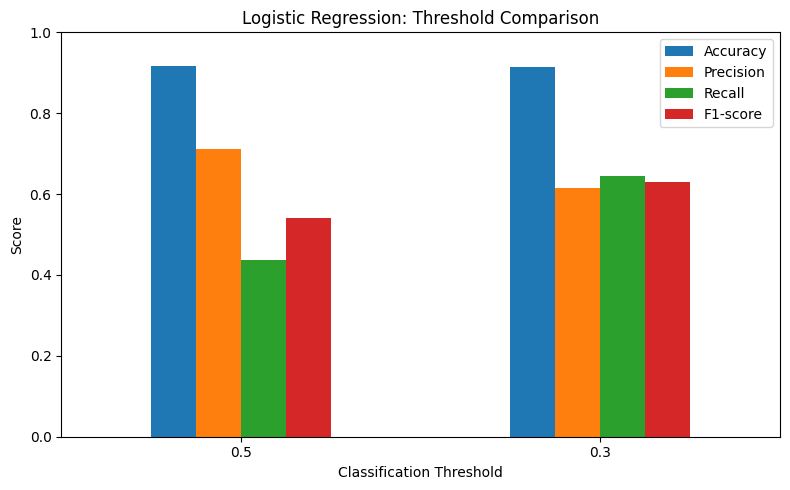

In [18]:
import matplotlib.pyplot as plt

# Plot the evaluation metrics for both thresholds
threshold_results.set_index('Threshold')[
    ['Accuracy', 'Precision', 'Recall', 'F1-score']
].plot(kind='bar', figsize=(8, 5))

plt.title('Logistic Regression: Threshold Comparison')
plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc='best')
plt.tight_layout()
plt.show()

In [19]:
# Create Logistic Regression models with L1 and L2 regularization
models = {
    'L1': LogisticRegression(
        penalty='l1', solver='liblinear', max_iter=2000
    ),
    'L2': LogisticRegression(
        penalty='l2', solver='lbfgs', max_iter=2000
    )
}

regularization_results = []
fitted_models = {}

# Train and evaluate both models
for name, classifier in models.items():
    model_pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', classifier)
    ])

    model_pipeline.fit(X_train, y_train)
    y_pred = model_pipeline.predict(X_test)

    fitted_models[name] = model_pipeline

    regularization_results.append({
        'Regularization': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-score': f1_score(y_test, y_pred, zero_division=0)
    })

regularization_results = pd.DataFrame(regularization_results)
print(regularization_results.round(4).to_string(index=False))

Regularization  Accuracy  Precision  Recall  F1-score
            L1    0.9166     0.7118  0.4364    0.5411
            L2    0.9166     0.7118  0.4364    0.5411


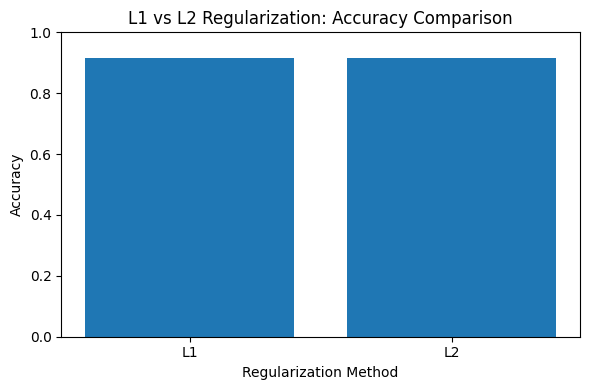

In [20]:
# Compare the accuracy of L1 and L2 models
plt.figure(figsize=(6, 4))

plt.bar(
    regularization_results['Regularization'],
    regularization_results['Accuracy']
)

plt.title('L1 vs L2 Regularization: Accuracy Comparison')
plt.xlabel('Regularization Method')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [21]:
# Extract feature names and coefficients from both models
feature_names = fitted_models['L1'].named_steps[
    'preprocessor'
].get_feature_names_out()

l1_coef = fitted_models['L1'].named_steps['classifier'].coef_[0]
l2_coef = fitted_models['L2'].named_steps['classifier'].coef_[0]

# Create a table to compare the coefficients
coefficient_comparison = pd.DataFrame({
    'Feature': feature_names,
    'L1 Coefficient': l1_coef,
    'L2 Coefficient': l2_coef
})

print(coefficient_comparison.round(4).to_string(index=False))

# Count coefficients that are zero or approximately zero
print("\nL1 zero coefficients:", np.isclose(l1_coef, 0).sum())
print("L2 near-zero coefficients:", (np.abs(l2_coef) < 1e-6).sum())

                           Feature  L1 Coefficient  L2 Coefficient
                   cat__job_admin.          0.0171         -0.0140
              cat__job_blue-collar         -0.2546         -0.2925
             cat__job_entrepreneur         -0.1683         -0.2217
                cat__job_housemaid         -0.0286         -0.0888
               cat__job_management          0.0000         -0.0359
                  cat__job_retired          0.3467          0.3243
            cat__job_self-employed         -0.1796         -0.2325
                 cat__job_services         -0.1219         -0.1619
                  cat__job_student          0.1604          0.1329
               cat__job_technician          0.0000         -0.0390
               cat__job_unemployed          0.0000         -0.0302
                  cat__job_unknown          0.0000         -0.0198
             cat__marital_divorced         -0.0741         -0.2321
              cat__marital_married         -0.0711         -0.